In [2]:
import os

print("Contents of /kaggle:", os.listdir('/kaggle'))
print("Contents of /kaggle/input:", os.listdir('/kaggle/input'))

# Search the whole filesystem for folders named rock/paper/scissors
for root, dirs, files in os.walk('/'):
    if root.startswith(('/proc', '/sys', '/usr', '/lib', '/opt')):
        dirs[:] = []
        continue
    for d in dirs:
        if d.lower() in ('rock', 'paper', 'scissors'):
            print("Found:", os.path.join(root, d))

Contents of /kaggle: ['lib', 'input', 'working']
Contents of /kaggle/input: ['datasets']
Found: /root/.julia/packages/Latexify/ZQKIY/paper
Found: /kaggle/input/datasets/wlsgur4011/rock-siccors-paper/rock_siccers_paper/paper
Found: /kaggle/input/datasets/wlsgur4011/rock-siccors-paper/rock_siccers_paper/rock


Folders found: ['paper', 'rock', 'siccers']
Paper: 257 images
Rock: 353 images
Scissors: 304 images
Total images: 914


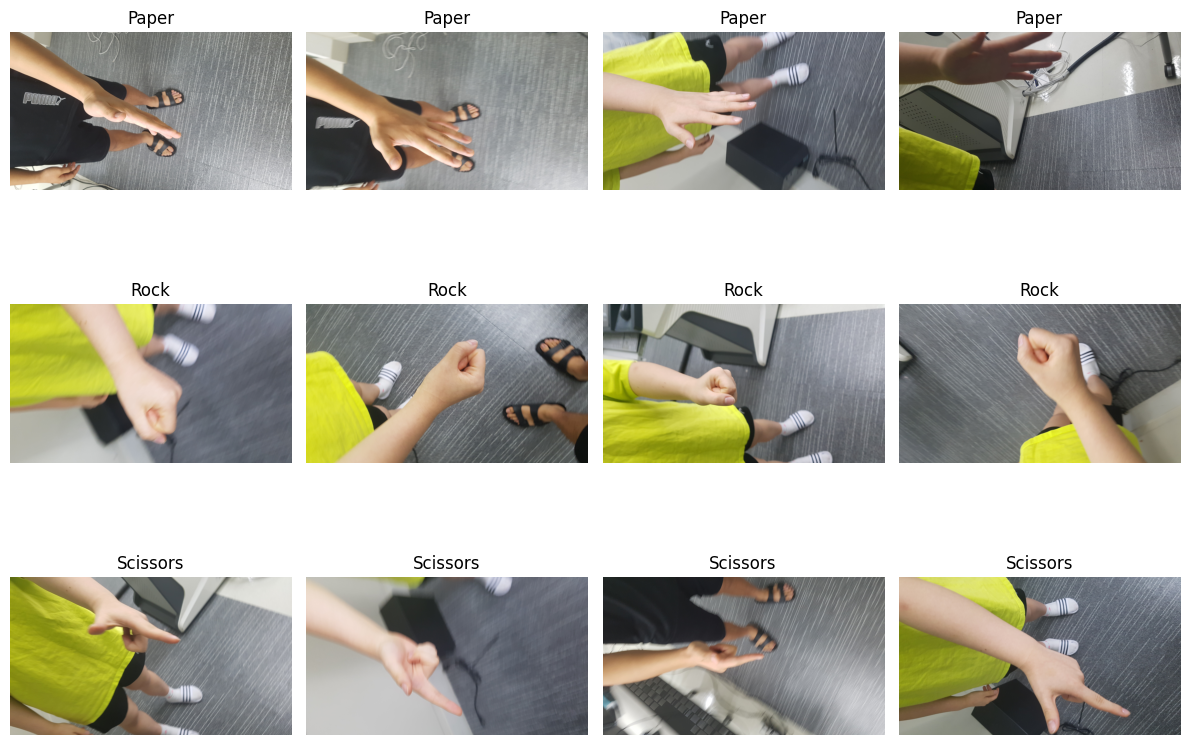

In [3]:
import os, random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

random.seed(42); np.random.seed(42); tf.random.set_seed(42)

BASE = '/kaggle/input/datasets/wlsgur4011/rock-siccors-paper/rock_siccers_paper'
IMG_EXT = ('.png', '.jpg', '.jpeg', '.bmp')
class_names = ['Paper', 'Rock', 'Scissors']

folders = [d for d in sorted(os.listdir(BASE)) if os.path.isdir(os.path.join(BASE, d))]
print("Folders found:", folders)
assert len(folders) == 3, "Expected exactly 3 class folders - check the folder list above"

def folder_to_class(name):
    n = name.lower()
    if 'rock' in n: return 'Rock'
    if 'paper' in n: return 'Paper'
    return 'Scissors'

assert len({folder_to_class(f) for f in folders}) == 3, "Could not map folders to 3 classes"

paths, labels = [], []
for f in folders:
    cls = folder_to_class(f)
    folder_path = os.path.join(BASE, f)
    for fname in sorted(os.listdir(folder_path)):
        if fname.lower().endswith(IMG_EXT):
            paths.append(os.path.join(folder_path, fname))
            labels.append(class_names.index(cls))
paths, labels = np.array(paths), np.array(labels)

for i, c in enumerate(class_names):
    print(f"{c}: {np.sum(labels == i)} images")
print("Total images:", len(paths))

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for i, c in enumerate(class_names):
    idx = np.random.choice(np.where(labels == i)[0], 4, replace=False)
    for j, k in enumerate(idx):
        axes[i, j].imshow(keras.utils.load_img(paths[k]))
        axes[i, j].set_title(c)
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

In [4]:
IMG_SIZE = 128

# Set aside 12 images (4 per class) for Task 6 - never used in training/testing
rest_paths, new_paths, rest_labels, new_labels = train_test_split(
    paths, labels, test_size=12, stratify=labels, random_state=42)

def load_image(path):
    img = keras.utils.load_img(path, target_size=(IMG_SIZE, IMG_SIZE))  # resize to 128x128 RGB
    return keras.utils.img_to_array(img) / 255.0                        # numpy array, values 0-1

X = np.array([load_image(p) for p in rest_paths], dtype='float32')
y = rest_labels

# 80% training / 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Pixel range:", X.min(), "to", X.max())
print("Labels: 0 = Paper, 1 = Rock, 2 = Scissors")
print("Held-out new images for Task 6:", len(new_paths))

X_train: (721, 128, 128, 3) | X_test: (181, 128, 128, 3)
Pixel range: 0.0 to 1.0
Labels: 0 = Paper, 1 = Rock, 2 = Scissors
Held-out new images for Task 6: 12


In [6]:
model = keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),         # input: 128x128 RGB image

    # Light augmentation (only active during training)
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),

    # Hidden layers: feature extraction
    layers.Conv2D(32, 3, activation='relu'),             # finds edges
    layers.MaxPooling2D(),                               # shrinks image, keeps strongest features
    layers.Conv2D(64, 3, activation='relu'),             # finds finger/hand parts
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu'),            # finds full hand shapes
    layers.MaxPooling2D(),

    # Hidden layers: classification
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),                                 # reduces overfitting

    # Output layer
    layers.Dense(3, activation='softmax')                # Paper / Rock / Scissors probabilities
])

model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5,
                                           restore_best_weights=True)

history = model.fit(X_train, y_train,
                    epochs=30, batch_size=32,
                    validation_data=(X_test, y_test),
                    callbacks=[early_stop])

model.save('/kaggle/working/rps_dnn_model.keras')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 128, 128, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 7s 53ms/step - accuracy: 0.4036 - loss: 1.1987 - val_accuracy: 0.5083 - val_loss: 0.9998
Epoch 2/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.4951 - loss: 1.0097 - val_accuracy: 0.4972 - val_loss: 0.9500
Epoch 3/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.5492 - loss: 0.9562 - val_accuracy: 0.5746 - val_loss: 0.8350
Epoch 4/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.6144 - loss: 0.8706 - val_accuracy: 0.7072 - val_loss: 0.6532
Epoch 5/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.6089 - loss: 0.8367 - val_accuracy: 0.8232 - val_loss: 0.5288
Epoch 6/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.6796 - loss: 0.7484 - val_accuracy: 0.8287 - val_loss: 0.5282
Epoch 7/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.6921 - loss: 0.7031 - val_accuracy: 0.8895 - val_loss: 0.4157
Epoch 8/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.7434 - loss: 0.6299 - val_accuracy: 0.8729 - v

Training accuracy: 0.9639
Testing accuracy:  0.9392


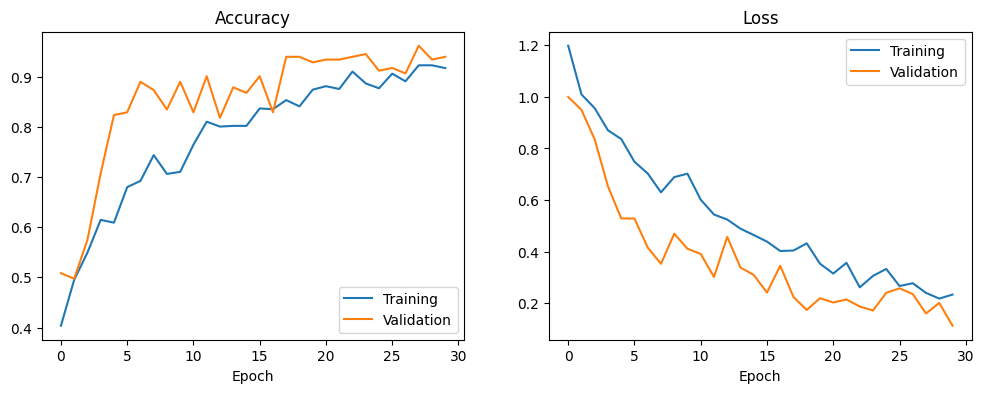

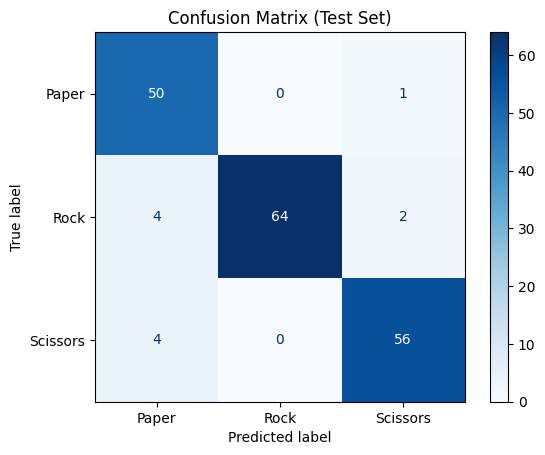

              precision    recall  f1-score   support

       Paper       0.86      0.98      0.92        51
        Rock       1.00      0.91      0.96        70
    Scissors       0.95      0.93      0.94        60

    accuracy                           0.94       181
   macro avg       0.94      0.94      0.94       181
weighted avg       0.94      0.94      0.94       181



In [7]:
train_loss, train_acc = model.evaluate(X_train, y_train, verbose=0)
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Training accuracy: {train_acc:.4f}")
print(f"Testing accuracy:  {test_acc:.4f}")

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Accuracy'); plt.xlabel('Epoch'); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Loss'); plt.xlabel('Epoch'); plt.legend()
plt.show()

y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap='Blues')
plt.title('Confusion Matrix (Test Set)')
plt.show()

print(classification_report(y_test, y_pred, target_names=class_names))

In [ ]:
# ============================================================
# Task 6: LIVE WEBCAM Rock Paper Scissors game
#
# This cell adds the game interface only. It reuses the CNN,
# class names, preprocessing and prediction helper defined above.
# It does NOT retrain or replace the model.
#
# Kaggle: the webcam is provided by Gradio (browser webcam),
#         because cv2.VideoCapture(0) cannot open the user's
#         camera inside a Kaggle notebook.
# Local : Gradio also works in Jupyter / VS Code and opens the
#         webcam in a browser tab.
# ============================================================

import os
import sys
import random
import subprocess
import numpy as np
from PIL import Image

# ------------------------------------------------------------
# 1. Check whether we are running in Kaggle or locally
# ------------------------------------------------------------
IS_KAGGLE = (
    os.path.isdir('/kaggle/input')
    or os.path.isdir('/kaggle/working')
    or 'KAGGLE_KERNEL_RUN_TYPE' in os.environ
)
ENV_NAME = 'Kaggle' if IS_KAGGLE else 'Local'
print('Environment detected:', ENV_NAME)
if IS_KAGGLE:
    print('Webcam: browser-based via Gradio (cv2.VideoCapture(0) cannot open your webcam on Kaggle).')
else:
    print('Webcam: browser-based via Gradio (works in Jupyter and VS Code).')

# ------------------------------------------------------------
# 2. Gradio (install once if it is missing)
# ------------------------------------------------------------
try:
    import gradio as gr
except ModuleNotFoundError:
    print('Gradio is not installed. Installing it now (one time only)...')
    try:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'gradio>=4'])
    except subprocess.CalledProcessError as error:
        raise RuntimeError(
            "Gradio could not be installed. Check your Internet connection, then run: "
            "!pip install -U 'gradio>=4'"
        ) from error
    import gradio as gr

GRADIO_MAJOR = int(gr.__version__.split('.')[0])
if GRADIO_MAJOR < 4:
    raise RuntimeError("This game needs Gradio 4 or newer. Run: !pip install -U 'gradio>=4'")

# Close an older copy of the game if this cell is re-run.
try:
    gr.close_all()
except Exception:
    pass

print('Gradio version:', gr.__version__)

# ------------------------------------------------------------
# 3. Reuse the trained model and its preprocessing
# ------------------------------------------------------------
required = ['model', 'class_names', 'load_image', 'IMG_SIZE', 'keras']
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        'Missing: ' + ', '.join(missing) + '. Run the notebook cells above '
        '(data, preprocessing and training) before starting the game. '
        'The model is not retrained here.'
    )

beats = {'Rock': 'Scissors', 'Paper': 'Rock', 'Scissors': 'Paper'}
TOTAL_ROUNDS = 5
CONFIDENCE_THRESHOLD = 60.0   # below this percentage, the round is not counted

print('Model ready | input shape:', (IMG_SIZE, IMG_SIZE, 3), '| classes:', class_names)


def predict_gesture(path):
    """Predict a gesture from an image file using the existing preprocessing."""
    probs = model.predict(np.expand_dims(load_image(path), 0), verbose=0)[0]
    return class_names[np.argmax(probs)], probs.max() * 100


def prepare_webcam_frame(frame):
    """Match load_image(): RGB, IMG_SIZE x IMG_SIZE, float32, values 0-1."""
    frame = np.asarray(frame)
    if frame.size == 0:
        raise ValueError('Empty webcam frame')

    image = Image.fromarray(frame.astype(np.uint8)).convert('RGB')
    image = image.resize((IMG_SIZE, IMG_SIZE), Image.NEAREST)   # same resize as load_image()
    array = keras.utils.img_to_array(image) / 255.0             # same dtype and scaling
    return np.expand_dims(array, axis=0)                        # (1, 128, 128, 3)


def predict_webcam_frame(frame):
    probs = model.predict(prepare_webcam_frame(frame), verbose=0)[0]
    index = int(np.argmax(probs))
    return class_names[index], float(probs[index]) * 100.0, probs


# ------------------------------------------------------------
# 4. Small HTML helpers for a clean interface
# ------------------------------------------------------------
def scoreboard_html(player_score, computer_score, rounds_played):
    if rounds_played >= TOTAL_ROUNDS:
        progress = 'Match complete'
    else:
        progress = f'Round {rounds_played + 1} of {TOTAL_ROUNDS}'
    return (
        '<div class="score-grid">'
        f'<div class="score-card"><div class="score-label">You</div>'
        f'<div class="score-value">{player_score}</div></div>'
        f'<div class="score-card"><div class="score-label">Computer</div>'
        f'<div class="score-value">{computer_score}</div></div>'
        f'<div class="score-card"><div class="score-label">Progress</div>'
        f'<div class="score-value small">{progress}</div></div>'
        '</div>'
    )


def intro_html():
    return (
        '<div class="result-card">'
        '<div class="result-title">Ready to play</div>'
        '<div class="result-line">Allow camera access, capture your hand, then press Play Round.</div>'
        f'<div class="result-sub">A match is {TOTAL_ROUNDS} rounds. Captures below '
        f'{CONFIDENCE_THRESHOLD:.0f}% confidence do not count.</div>'
        '</div>'
    )


def result_card(title, card_class, player_text, computer_text, note, extra=''):
    return (
        f'<div class="result-card {card_class}">'
        f'<div class="result-title">{title}</div>'
        f'<div class="result-line"><b>You:</b> {player_text}</div>'
        f'<div class="result-line"><b>Computer:</b> {computer_text}</div>'
        f'<div class="result-sub">{note}</div>'
        f'{extra}'
        '</div>'
    )


def final_result_html(player_score, computer_score):
    if player_score > computer_score:
        title, css = 'FINAL RESULT: YOU WIN THE MATCH', 'win'
    elif computer_score > player_score:
        title, css = 'FINAL RESULT: COMPUTER WINS THE MATCH', 'lose'
    else:
        title, css = 'FINAL RESULT: MATCH DRAW', 'draw'
    return (
        f'<div class="final-line {css}">{title}<br>'
        f'<span class="final-sub">Final score: You {player_score} - {computer_score} Computer. '
        'Press Play Again for a rematch.</span></div>'
    )


# ------------------------------------------------------------
# 5. Game logic
# ------------------------------------------------------------
def play_round(frame, player_score, computer_score, rounds_played):
    scoreboard = scoreboard_html(player_score, computer_score, rounds_played)

    if rounds_played >= TOTAL_ROUNDS:
        return (
            frame,
            result_card('MATCH ALREADY FINISHED', 'draw', '-', '-',
                        'Press Play Again to start a new match.',
                        final_result_html(player_score, computer_score)),
            {},
            scoreboard,
            player_score, computer_score, rounds_played,
        )

    if frame is None:
        return (
            None,
            result_card('NO FRAME CAPTURED', 'unclear', '-', 'not played',
                        'Allow webcam access, capture your hand, then press Play Round.'),
            {},
            scoreboard,
            player_score, computer_score, rounds_played,
        )

    try:
        frame_array = np.asarray(frame)
        if float(frame_array.astype(np.float32).std()) < 4.0:
            return (
                frame,
                result_card('UNCLEAR IMAGE', 'unclear', '-', 'not played',
                            'The camera image looks blank. Check the lighting and capture again.'),
                {},
                scoreboard,
                player_score, computer_score, rounds_played,
            )
        player, confidence, probs = predict_webcam_frame(frame)
    except Exception as error:
        print('Prediction error:', error)
        return (
            frame,
            result_card('PREDICTION FAILED', 'unclear', '-', 'not played',
                        'The model could not read this frame. Please capture again.'),
            {},
            scoreboard,
            player_score, computer_score, rounds_played,
        )

    probs_dict = {name: float(p) for name, p in zip(class_names, probs)}

    if confidence < CONFIDENCE_THRESHOLD:
        return (
            frame,
            result_card('UNCLEAR GESTURE', 'unclear',
                        f'{player} ({confidence:.1f}%)', 'not played',
                        f'Best guess was {player} at {confidence:.1f}%, below the '
                        f'{CONFIDENCE_THRESHOLD:.0f}% threshold. This round was not counted. '
                        'Move closer, improve the lighting and try again.'),
            probs_dict,
            scoreboard,
            player_score, computer_score, rounds_played,
        )

    computer = random.choice(class_names)
    rounds_played += 1

    if player == computer:
        title, card_class = 'DRAW', 'draw'
        note = f'Both of you showed {player}.'
    elif beats[player] == computer:
        title, card_class = 'YOU WIN THE ROUND', 'win'
        player_score += 1
        note = f'{player} beats {computer}.'
    else:
        title, card_class = 'COMPUTER WINS THE ROUND', 'lose'
        computer_score += 1
        note = f'{computer} beats {player}.'

    extra = final_result_html(player_score, computer_score) if rounds_played >= TOTAL_ROUNDS else ''

    return (
        frame,
        result_card(title, card_class, f'{player} ({confidence:.1f}%)', computer, note, extra),
        probs_dict,
        scoreboard_html(player_score, computer_score, rounds_played),
        player_score, computer_score, rounds_played,
    )


def reset_match():
    return (
        None,
        None,
        intro_html(),
        {},
        scoreboard_html(0, 0, 0),
        0, 0, 0,
    )


# ------------------------------------------------------------
# 6. Build and launch the Gradio interface
# ------------------------------------------------------------
GAME_CSS = """
.gradio-container { max-width: 1150px !important; margin: auto; }
.rps-header { text-align: center; padding: 10px 0 4px; }
.rps-header h1 { margin: 0; font-size: 2.1rem; font-weight: 800; letter-spacing: -0.02em; }
.rps-sub { color: #64748b; margin-top: 4px; font-size: 0.98rem; }
.rps-env { display: inline-block; margin-top: 8px; padding: 4px 12px; border-radius: 999px;
           background: #eef2ff; color: #3730a3; font-size: 0.82rem; font-weight: 600; }
.score-grid { display: flex; gap: 10px; margin: 2px 0 6px; }
.score-card { flex: 1; text-align: center; padding: 10px 8px; border-radius: 12px;
              background: #f8fafc; border: 1px solid #e2e8f0; }
.score-label { font-size: 0.74rem; color: #64748b; text-transform: uppercase; letter-spacing: 0.05em; }
.score-value { font-size: 1.55rem; font-weight: 800; color: #0f172a; line-height: 1.2; }
.score-value.small { font-size: 0.95rem; padding-top: 9px; }
.result-card { border-radius: 14px; border: 1px solid #e2e8f0; padding: 18px;
               background: #f8fafc; text-align: center; }
.result-card.win { background: #ecfdf5; border-color: #34d399; }
.result-card.lose { background: #fef2f2; border-color: #f87171; }
.result-card.draw { background: #fffbeb; border-color: #fbbf24; }
.result-card.unclear { background: #eff6ff; border-color: #60a5fa; }
.result-title { font-size: 1.35rem; font-weight: 800; margin-bottom: 8px; color: #0f172a; }
.result-card.win .result-title { color: #047857; }
.result-card.lose .result-title { color: #b91c1c; }
.result-card.draw .result-title { color: #b45309; }
.result-card.unclear .result-title { color: #1d4ed8; }
.result-line { font-size: 1rem; color: #1e293b; margin: 4px 0; }
.result-sub { font-size: 0.9rem; color: #64748b; margin-top: 8px; line-height: 1.45; }
.final-line { margin-top: 12px; padding-top: 12px; border-top: 1px dashed #cbd5e1;
              font-weight: 800; font-size: 1.05rem; color: #0f172a; }
.final-line.win { color: #047857; }
.final-line.lose { color: #b91c1c; }
.final-line.draw { color: #b45309; }
.final-sub { display: inline-block; margin-top: 6px; font-weight: 500; font-size: 0.85rem; color: #64748b; }
.howto { text-align: center; color: #475569; font-size: 0.88rem; margin-bottom: 4px; }
"""

ENV_NOTE = (
    'Browser webcam through Gradio. Kaggle cannot use cv2.VideoCapture(0).'
    if IS_KAGGLE else
    'Browser webcam through Gradio - works in Jupyter, JupyterLab and VS Code.'
)

HEADER_HTML = f"""
<div class="rps-header">
  <h1>Rock Paper Scissors</h1>
  <div class="rps-sub">Live webcam edition - your trained CNN makes the prediction</div>
  <div class="rps-env">Environment: {ENV_NAME}</div>
</div>
"""

# Gradio 6 moved theme/css from Blocks() to launch(). Keep both versions working.
if GRADIO_MAJOR >= 6:
    blocks_style = {}
    launch_style = {'theme': 'soft', 'css': GAME_CSS}
else:
    blocks_style = {'theme': 'soft', 'css': GAME_CSS}
    launch_style = {}

with gr.Blocks(title='Rock Paper Scissors - Live Webcam', **blocks_style) as demo:
    gr.HTML(HEADER_HTML)
    gr.HTML(f'<div class="howto">{ENV_NOTE}</div>')

    player_score_state = gr.State(0)
    computer_score_state = gr.State(0)
    rounds_played_state = gr.State(0)

    with gr.Row():
        with gr.Column(scale=3):
            webcam = gr.Image(
                sources=['webcam'],
                type='numpy',
                label='Webcam - capture your hand',
                height=370,
            )
            with gr.Row():
                play_btn = gr.Button('Play Round', variant='primary', scale=2)
                reset_btn = gr.Button('Play Again / Reset Match', scale=1)
            gr.Markdown(
                '**How to play**  \n'
                '1. Click the webcam area and allow camera access.  \n'
                '2. Show Rock, Paper or Scissors.  \n'
                '3. Click the camera button inside the webcam box to capture a still frame.  \n'
                '4. Press **Play Round**.  \n'
                f'If the model is less than {CONFIDENCE_THRESHOLD:.0f}% confident, '
                'the round is not counted - capture again.  \n'
                '**Tips:** fill most of the frame with your hand, keep the background '
                'simple and use good lighting.'
            )
        with gr.Column(scale=2):
            scoreboard = gr.HTML(scoreboard_html(0, 0, 0))
            captured = gr.Image(label='Captured frame', interactive=False, height=235)
            result = gr.HTML(intro_html())
            probabilities = gr.Label(num_top_classes=3, label='Model confidence')

    play_btn.click(
        fn=play_round,
        inputs=[webcam, player_score_state, computer_score_state, rounds_played_state],
        outputs=[captured, result, probabilities, scoreboard,
                 player_score_state, computer_score_state, rounds_played_state],
        show_progress='minimal',
    )
    reset_btn.click(
        fn=reset_match,
        inputs=None,
        outputs=[webcam, captured, result, probabilities, scoreboard,
                 player_score_state, computer_score_state, rounds_played_state],
        show_progress='minimal',
    )

demo.queue()

print('\nStarting the game server...')
try:
    demo.launch(
        share=IS_KAGGLE,
        inline=False,
        inbrowser=not IS_KAGGLE,
        prevent_thread_lock=True,
        quiet=False,
        **launch_style,
    )
    print('\nGame started.')
    if IS_KAGGLE:
        print('Open the public gradio.live link printed above. If no link appears, '
              'enable Internet in Notebook Settings and re-run this cell.')
    else:
        print('A browser tab should open automatically. If it does not, open the local URL printed above.')
    print('The game keeps running in the browser. Restart the kernel to stop it.')
except Exception as error:
    print('Could not start the Gradio server:', error)
    if IS_KAGGLE:
        print('Kaggle tip: enable Internet in Notebook Settings, then re-run this cell.')
    print("You can install/upgrade Gradio with: !pip install -U 'gradio>=4'")

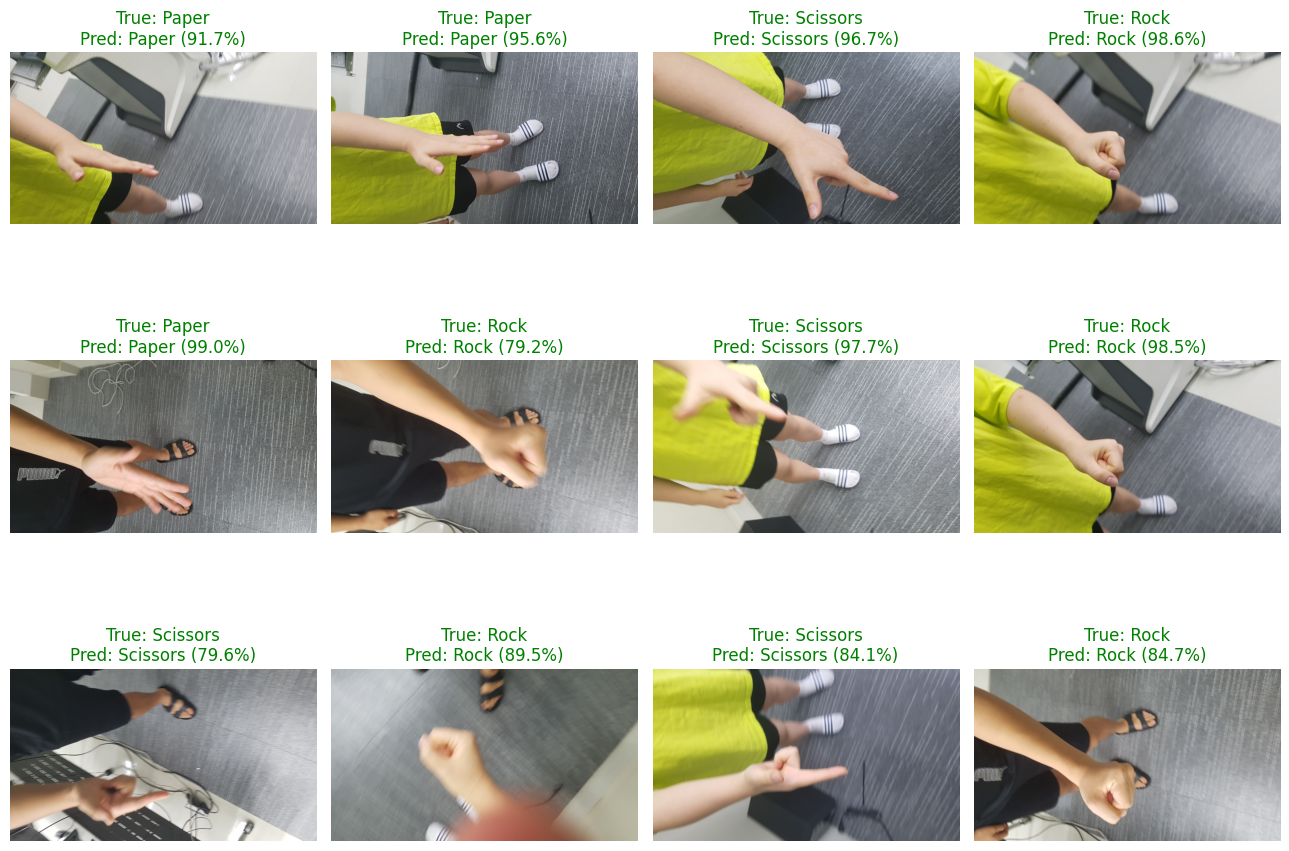

Correct: 12/12
Add your own image paths to MY_IMAGES.


In [10]:
# Part A: 12 dataset images never used in training or testing
fig, axes = plt.subplots(3, 4, figsize=(13, 10))
correct = 0
for ax, p, true_label in zip(axes.flat, new_paths, new_labels):
    pred, conf = predict_gesture(p)
    ok = pred == class_names[true_label]
    correct += ok
    ax.imshow(keras.utils.load_img(p))
    ax.set_title(f"True: {class_names[true_label]}\nPred: {pred} ({conf:.1f}%)",
                 color='green' if ok else 'red')
    ax.axis('off')
plt.tight_layout()
plt.show()
print(f"Correct: {correct}/{len(new_paths)}")

# Part B: your own photos (quiz requires at least 5) - add their paths here
MY_IMAGES = [
    # '/kaggle/input/.../my1.jpg',
]
if MY_IMAGES:
    plt.figure(figsize=(4 * len(MY_IMAGES), 4))
    for i, p in enumerate(MY_IMAGES):
        pred, conf = predict_gesture(p)
        plt.subplot(1, len(MY_IMAGES), i + 1)
        plt.imshow(keras.utils.load_img(p))
        plt.title(f"{pred} ({conf:.1f}%)")
        plt.axis('off')
    plt.show()
else:
    print("Add your own image paths to MY_IMAGES.")

In [11]:
import gradio as gr
gr.close_all()

Closing server running on port: 7860
